In [1]:
import json
import os
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from src.data_loader import load_processed_data
from src.synthetic_data_generation import build_template_sets_from_data

# Get the current working directory
current_dir = Path.cwd()

# If the notebook is running inside the 'notebooks' folder, step up one level to the parent dir
if current_dir.name == "notebooks":
    os.chdir(current_dir.parent)
    print(f"Changed working directory to: {Path.cwd()}")
else:
    print(f"Working directory is already: {Path.cwd()}")

Changed working directory to: C:\Users\Matej\Documents\GitHub\MasterThesis\MasterThesis


In [2]:
raw_data_path = Path("data") / "01_raw" / "fire_train.json"

with open(raw_data_path, 'r', encoding='utf-8') as f:
    raw_data = json.load(f)

print(len(raw_data))

2117


In [2]:
data_path = Path("data") / "02_processed" / "fire_all_processed.json"
data = load_processed_data(data_path)

allowed_ontology_path = "data/03_synthetic/allowed_schemas_cutoff_2.0%.json"
with open(allowed_ontology_path, "r", encoding="utf-8") as f:
    allowed_schemas = json.load(f)

template_schema_path = "data/03_synthetic/allowed_schemas_template.json"
with open(template_schema_path, "r", encoding="utf-8") as f:
    allowed_schemas_template = json.load(f)

In [3]:
unique_relations = set()
unique_entity_types = set()

for sample in data:
    # sample is a SentenceSample object
    for triplet in sample.triplets:
        # triplet is a Triplet object
        if triplet.relation:
            unique_relations.add(triplet.relation)
        if triplet.subject_type:
            unique_entity_types.add(triplet.subject_type)
        if triplet.object_type:
            unique_entity_types.add(triplet.object_type)

print(f"Total Samples: {len(data)}")
print(f"Unique Relations ({len(unique_relations)}): {sorted(unique_relations)}")
print(f"Unique Entity Types ({len(unique_entity_types)}): {sorted(unique_entity_types)}")

Total Samples: 2828
Unique Relations (18): ['ActionBuy', 'ActionMerge', 'ActionSell', 'Actionin', 'Actionto', 'Constituentof', 'Designation', 'Employeeof', 'Locatedin', 'Productof', 'Propertyof', 'Quantity', 'Sector', 'Subsidiaryof', 'Value', 'ValueChangeDecreaseby', 'ValueChangeIncreaseby', 'Valuein']
Unique Entity Types (13): ['Action', 'BusinessUnit', 'Company', 'Date', 'Designation', 'FinancialEntity', 'GeopoliticalEntity', 'Location', 'Money', 'Person', 'Product', 'Quantity', 'Sector']


Total Sentences Analyzed: 2,828

Triplet Count Distribution:
  0 triplet(s): 288 sentences
  1 triplet(s): 679 sentences
  2 triplet(s): 638 sentences
  3 triplet(s): 447 sentences
  4 triplet(s): 322 sentences
  5 triplet(s): 169 sentences
  6 triplet(s): 142 sentences
  7 triplet(s): 54 sentences
  8 triplet(s): 30 sentences
  9 triplet(s): 24 sentences
  10 triplet(s): 18 sentences
  11 triplet(s): 6 sentences
  12 triplet(s): 2 sentences
  13 triplet(s): 1 sentences
  14 triplet(s): 2 sentences
  15 triplet(s): 3 sentences
  16 triplet(s): 2 sentences
  17 triplet(s): 1 sentences


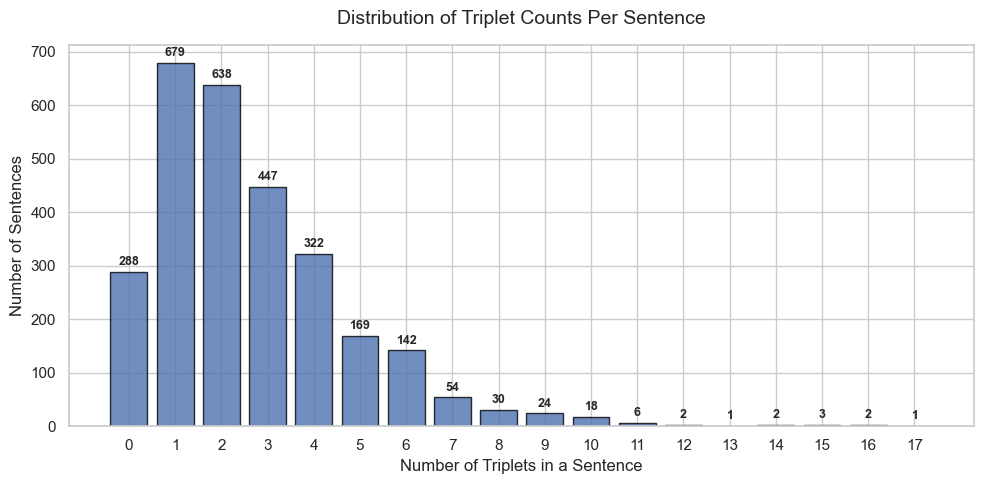

In [4]:
# 1. Calculate triplet count distribution
triplet_counts = Counter(len(sample.triplets) for sample in data)
sorted_counts = sorted(triplet_counts.items())

# 2. Print the formatted counts
print(f"Total Sentences Analyzed: {len(data):,}\n")
print("Triplet Count Distribution:")
for count, occurrences in sorted_counts:
    print(f"  {count} triplet(s): {occurrences:,} sentences")

# 3. Create the plot
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

# Extract X and Y for plotting
x_vals = [item[0] for item in sorted_counts]
y_vals = [item[1] for item in sorted_counts]

# Plot bars
bars = plt.bar(x_vals, y_vals, color="#4C72B0", edgecolor="black", alpha=0.8)

# Add value labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + (max(y_vals) * 0.01),
             f"{yval:,}", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title("Distribution of Triplet Counts Per Sentence", fontsize=14, pad=15)
plt.xlabel("Number of Triplets in a Sentence", fontsize=12)
plt.ylabel("Number of Sentences", fontsize=12)
plt.xticks(x_vals)
plt.tight_layout()
plt.show()

Total Sentences (with 1 to 5 triplets): 2,255

Triplet Count Distribution (1 to 5):
  1 triplet(s): 679 sentences (30.11%)
  2 triplet(s): 638 sentences (28.29%)
  3 triplet(s): 447 sentences (19.82%)
  4 triplet(s): 322 sentences (14.28%)
  5 triplet(s): 169 sentences (7.49%)


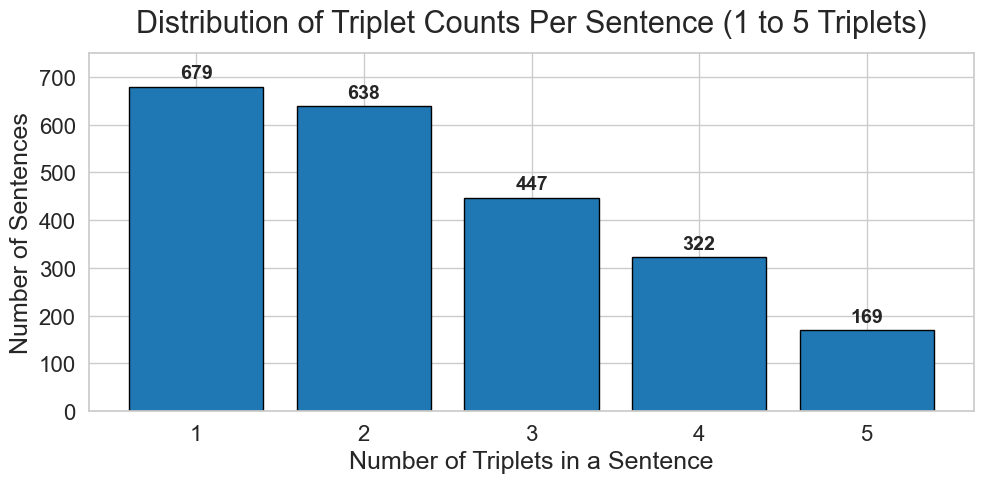

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# 1. Calculate triplet count distribution (Assuming 'data' is already defined)
triplet_counts = Counter(len(sample.triplets) for sample in data)
sorted_counts = sorted(triplet_counts.items())

# --- Filter for counts 1 to 5 only ---
filtered_counts = [(c, o) for c, o in sorted_counts if 1 <= c <= 5]

# Calculate the total occurrences strictly for 1-5 to make percentages sum to 100%
total_filtered = sum(occurrences for count, occurrences in filtered_counts)

# 2. Print the formatted counts and percentages
print(f"Total Sentences (with 1 to 5 triplets): {total_filtered:,}\n")
print("Triplet Count Distribution (1 to 5):")
for count, occurrences in filtered_counts:
    percentage = (occurrences / total_filtered) * 100
    print(f"  {count} triplet(s): {occurrences:,} sentences ({percentage:.2f}%)")

# 3. Create the plot
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

# Extract X and Y for plotting from the filtered data
x_vals = [item[0] for item in filtered_counts]
y_vals = [item[1] for item in filtered_counts]

# Plot bars
bars = plt.bar(x_vals, y_vals, color="#1F77B4", edgecolor="black", alpha=1)

# --- NEW: Extend Y-axis limit to 525 to add top margin ---
plt.ylim(0, 750)

# Add value labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    # NEW: Increased fontsize to 12 (was 9)
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 10,
             f"{yval:,}", ha='center', va='bottom', fontsize=14, fontweight='bold')

# NEW: Increased title and axis label fontsizes
plt.title("Distribution of Triplet Counts Per Sentence (1 to 5 Triplets)", fontsize=22, pad=15)
plt.xlabel("Number of Triplets in a Sentence", fontsize=18)
plt.ylabel("Number of Sentences", fontsize=18)

# NEW: Explicitly increased tick fontsizes
plt.xticks(x_vals, fontsize=16)
plt.yticks(fontsize=16)

plt.tight_layout()
plt.show()

In [6]:
# 1. Generate the templates using your function
templates_by_length = build_template_sets_from_data(data, include_types=True, max_triplets=5)

print("\n" + "="*50)
print("  FILTERING TEMPLATES AGAINST ALLOWED SCHEMAS")
print("="*50)

# Convert allowed schemas list to a set for O(1) lightning-fast lookups
allowed_set = set(allowed_schemas)

# Track global metrics
total_valid_templates_count = 0
total_templates_count = 0

# 2. Iterate through each template length group to check validity
for length in sorted(templates_by_length.keys()):
    group = templates_by_length[length]
    templates = group["templates"]
    weights = group["weights"]

    valid_templates = []
    valid_weights = []
    invalid_count = 0

    # Check every template configuration in this length group
    for template, weight in zip(templates, weights):
        # A template is valid ONLY if every single signature inside it is allowed
        is_template_valid = all(sig in allowed_set for sig in template)

        if is_template_valid:
            valid_templates.append(template)
            valid_weights.append(weight)
        else:
            invalid_count += 1

    total_valid_templates_count += len(valid_templates)
    total_templates_count += len(templates)

    # Print findings for this specific length group
    print(f"\n--- Length {length} Templates Summary ---")
    print(f"  Total Unique Templates Evaluated : {len(templates)}")
    print(f"  Strictly Valid Templates (ALL OK): {len(valid_templates)}")
    print(f"  Invalid/Filtered Templates       : {invalid_count}")

    # Optional: Print a quick sneak peek of a valid template pattern if any exist
    if valid_templates:
        print("  Example Valid Template Structure:")
        print(f"    {valid_templates[0]}")

print("\n" + "="*50)
print(f"Filtering Complete. Found {total_valid_templates_count} total valid templates across lengths 1-5.")
print(f"In total, {total_templates_count} templates are being used.")
print("="*50)

Length 3: Found 179 unique templates from 447 sentences.
Length 2: Found 138 unique templates from 638 sentences.
Length 4: Found 182 unique templates from 322 sentences.
Length 5: Found 131 unique templates from 169 sentences.
Length 1: Found 34 unique templates from 679 sentences.

  FILTERING TEMPLATES AGAINST ALLOWED SCHEMAS

--- Length 1 Templates Summary ---
  Total Unique Templates Evaluated : 34
  Strictly Valid Templates (ALL OK): 16
  Invalid/Filtered Templates       : 18
  Example Valid Template Structure:
    ('[Company] --(Sector)--> [Sector]',)

--- Length 2 Templates Summary ---
  Total Unique Templates Evaluated : 138
  Strictly Valid Templates (ALL OK): 51
  Invalid/Filtered Templates       : 87
  Example Valid Template Structure:
    ('[FinancialEntity] --(Propertyof)--> [Company]', '[FinancialEntity] --(Value)--> [Money]')

--- Length 3 Templates Summary ---
  Total Unique Templates Evaluated : 179
  Strictly Valid Templates (ALL OK): 66
  Invalid/Filtered Templates 